In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
# parameters
mu = 0.5                                      # Mean Number of Photons/Pulse
alpha = 0.2                                   # Attenuation in fiber in dB/Km
delta_f = 1e3                                 # Linewidth in Hz
d_t = 1e-9                                    # 1/Bit rate
R_b = 1e9                                     # Bit rate
L = 80                                        # Length of Fiber
t_B = 0.5                                     # Transmittance of BS
loss_MZI = 1 * 10**(-0.2)                     # 2 dB loss in MZI
theta = 0                                     # Phase difference of two consecutive pulses
eta_values =  np.arange(0.1, 1, 0.01)        # Efficiency of SPD
Pd_values = np.arange(2e-7, 10.0001e-7, 0.1e-7) # Dark Count Probability
t_d = np.arange(10e-9, 50e-6, 100e-9)    # Dead Time in SPD
duty_cycle_TTL = 0.75                         # Duty cycle of TTL pulses
                                    
X = []
Y = []
Z = []
Color = []

for P_d in Pd_values:

    for eta in eta_values:

        # Phase Noise at LASER
        sigma = np.sqrt(2 * np.pi * delta_f * d_t)

        # Channel transmittance
        eta_channel = 10 ** (-alpha * L / 10)

        Photon_count_after_channel = mu * 10 ** (-alpha * L / 10) * R_b
        
        # DATA LINE

        Photon_count_after_BS = mu * 10 ** (-alpha * L / 10) * R_b * t_B

        Photon_count_after_D_d = Photon_count_after_BS * eta + P_d * R_b

        effective_time_difference_D_d = 1 / Photon_count_after_D_d + t_d

        effective_counts_D_d = (1 / effective_time_difference_D_d) * duty_cycle_TTL
        # Error Counts at the D_d
        E_C_D_d = ((P_d * R_b * np.exp(-mu * eta_channel * eta * t_B))/(1 + t_d * P_d * R_b * np.exp(-mu * eta_channel * eta * t_B))) * duty_cycle_TTL
        # QBER
        Q_0 = (E_C_D_d)/effective_counts_D_d;
        Q = Q_0 * 100;
        
        X.extend(t_d * 1e6)
        Y.extend(np.ones_like(t_d) * eta)
        Z.extend(np.ones_like(t_d) * P_d * 1e7)
        Color.extend(Q)


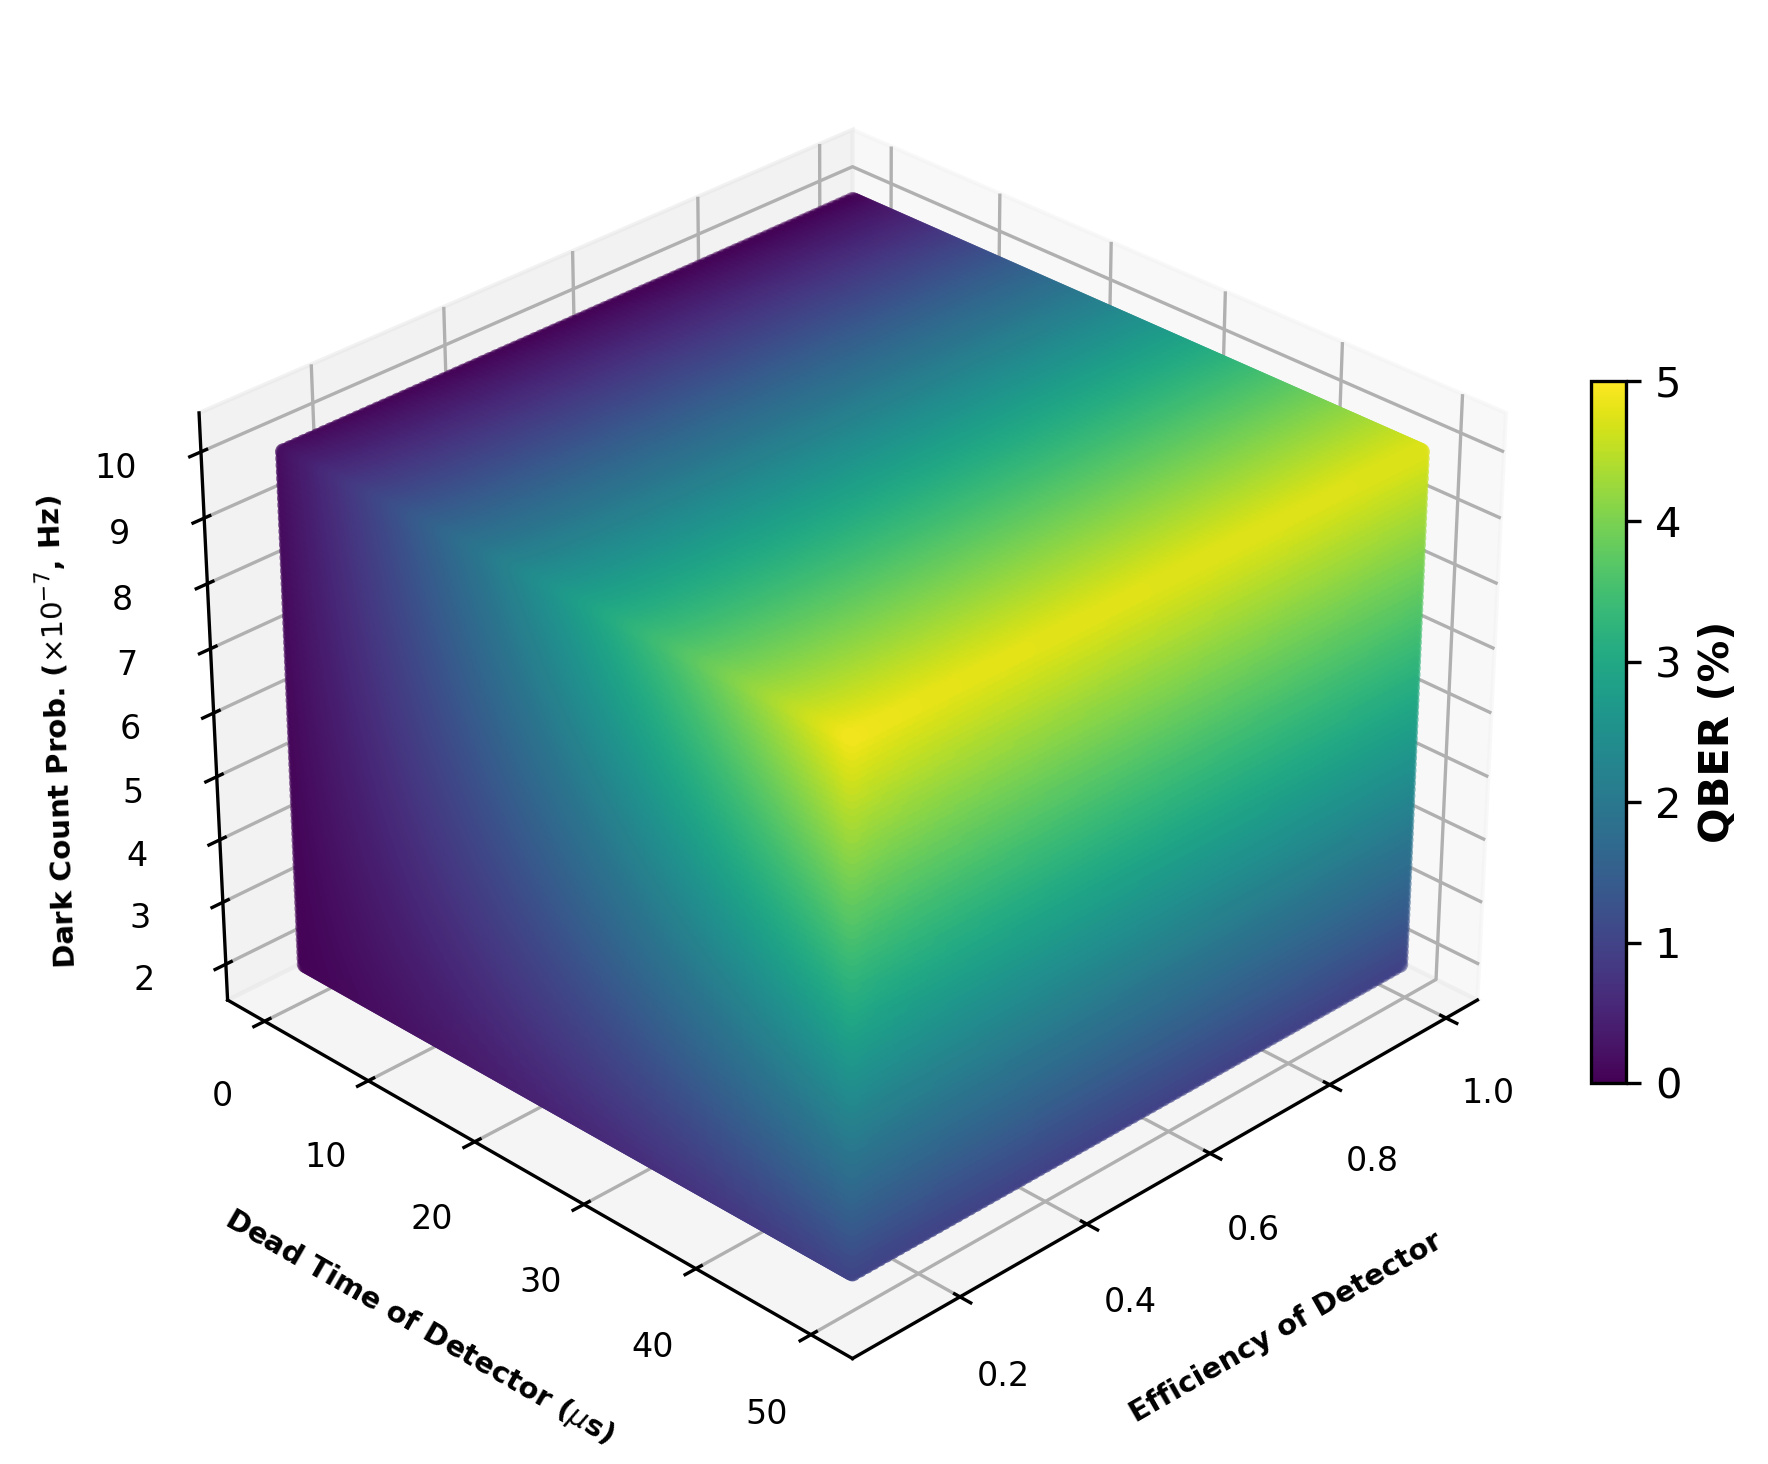

In [2]:
# Plot
from matplotlib.colors import Normalize
Color = np.asarray(Color)
vmin, vmax = np.percentile(Color, [5, 95])
if np.isclose(vmin, vmax):
    vmin, vmax = Color.min(), Color.max()
fig = plt.figure(figsize=(9, 6.5), dpi=300)
ax = fig.add_axes([0.16, 0.16, 0.68, 0.72], projection="3d")
sc = ax.scatter(
    Y, X, Z,
    c=Color,
    cmap="viridis",                 
    norm=Normalize(vmin=0, vmax=5),
    s=18,
    edgecolors="none"
)
ax.set_xlabel('Efficiency of Detector', fontsize=7, labelpad=8, fontweight='bold')
ax.set_ylabel('Dead Time of Detector ($\mu$s)', fontsize=7, labelpad=8, fontweight='bold')
ax.set_zticks(np.arange(2, 11, 1))
ax.invert_xaxis()
ax.view_init(elev=30, azim=45)
ax.tick_params(axis="both", labelsize=8)
ax.tick_params(axis="z", labelsize=8)
fig.text(0.16,0.52,r'Dark Count Prob. ($\times 10^{-7}$, Hz)',rotation=92,fontsize=7,va='center',fontweight='bold')
cbar = fig.colorbar(sc, ax=ax, shrink=0.50, pad=0.03)
cbar.set_label("QBER (%)", fontsize=10, fontweight="bold")
plt.savefig("QBER_plot_eta_t_d_P_d.png", dpi=300, bbox_inches="tight")
plt.show()